# Practice Notebook 3.1: One-Way ANOVA by Hand and from Scratch

Advanced Statistics Course, Brain Science, Period 2 (Week 3 practice)

This notebook trains the **mechanics** of one-way ANOVA: why we need it instead of many t-tests, how the variance is partitioned, how the ANOVA table is built, and how the F-distribution is used to make a decision.
You will first do things with paper and pencil, then rebuild the same computations in Python so you can check yourself.

Please note: paper-and-pencil questions are followed directly by an **Answer** cell. For coding tasks, first work in the empty task cell(s), then compare with the **Solution** cell(s) below them.

In [ ]:
# Before running the analyses, we need to install a few Python libraries.
# Run the following command in your terminal or Jupyter Notebook (only needed once):
%pip install pandas numpy scipy matplotlib seaborn pingouin statsmodels

### Part 1: Why not just run t-tests? (paper and pencil)

A perception lab measures **pitch-discrimination thresholds** (in cents) in **4 groups** of participants: non-musicians, amateur musicians, semi-professional musicians and professional musicians.
A follow-up study extends this to **6 groups** (adding singers and DJs).

A student suggests comparing every pair of groups with independent-samples t-tests at $\alpha = .05$.

**Questions**

1. How many pairwise t-tests are needed for 4 groups? For 6 groups? (Hint: $m = \frac{k(k-1)}{2}$.)
2. Assuming the tests are independent, what is the probability of making **at least one** Type I error (familywise error rate) in each study?
3. If you insisted on running all t-tests in the 6-group study, what per-test significance level would a Bonferroni correction require?
4. The one-way ANOVA on the 4-group study is significant. Can you conclude that all four groups differ from each other? What is the next step?

**Answer**

1. Number of tests:
   - 4 groups: $m = \frac{4 \cdot 3}{2} = 6$ tests
   - 6 groups: $m = \frac{6 \cdot 5}{2} = 15$ tests

2. Familywise error rate $= 1 - (1-\alpha)^m$:
   - 4 groups: $1 - 0.95^{6} = 1 - 0.735 = 0.265$ (≈ 26.5%)
   - 6 groups: $1 - 0.95^{15} = 1 - 0.463 = 0.537$ (≈ 53.7%)

   With 6 groups, it is more likely than not that at least one "significant" difference is a false positive.

3. Bonferroni: $\alpha_{\text{per test}} = \frac{0.05}{15} \approx 0.0033$.

4. No. ANOVA is an **omnibus** test: rejecting $H_0$ only means that **at least one** group mean differs. The next step is a **post-hoc test** (e.g., Tukey HSD) to locate which pairs differ.

### Part 2: One-way ANOVA by hand: speech perception in noise

Participants listened to 10 spoken words embedded in background babble and repeated as many as they could.
Each participant was tested in only **one** noise condition (between-subjects), with **4 participants per group**.

| Group | $X_1$ | $X_2$ | $X_3$ | $X_4$ |
|---|---|---|---|---|
| Quiet | 8 | 9 | 7 | 8 |
| Moderate noise | 6 | 7 | 5 | 6 |
| Loud noise | 4 | 5 | 3 | 4 |

**Task:** Complete the ANOVA table and draw a conclusion at $\alpha = .05$. The critical value is $F_{crit}(2, 9) = 4.26$.

| Source | SS | df | MS | F |
|---|---|---|---|---|
| Between | ? | ? | ? | ? |
| Within | ? | ? | ? | |
| Total | ? | ? | | |

**Hints**
1. Compute the group means and the grand mean first.
2. $SS_{between} = \sum n_i(\bar X_i - \bar X)^2$, $SS_{within} = \sum_i \sum_j (X_{ij} - \bar X_i)^2$.
3. Check your work: $SS_{total} = \sum (X_{ij} - \bar X)^2$ must equal $SS_{between} + SS_{within}$.
4. State $H_0$ and $H_1$ before deciding.

**Answer**

**Hypotheses:** $H_0: \mu_{Quiet} = \mu_{Moderate} = \mu_{Loud}$; $H_1$: at least one mean differs.

**Step 1: Means**
- $\bar X_{Quiet} = 32/4 = 8$, $\bar X_{Moderate} = 24/4 = 6$, $\bar X_{Loud} = 16/4 = 4$
- Grand mean $\bar X = 72/12 = 6$ (equal $n$, so also the mean of the group means)

**Step 2: Between-groups SS**

$SS_B = 4(8-6)^2 + 4(6-6)^2 + 4(4-6)^2 = 16 + 0 + 16 = 32$

**Step 3: Within-groups SS**
- Quiet: $(0)^2 + (1)^2 + (-1)^2 + (0)^2 = 2$
- Moderate: $0 + 1 + 1 + 0 = 2$
- Loud: $0 + 1 + 1 + 0 = 2$

$SS_W = 2 + 2 + 2 = 6$

**Step 4: Check with total SS**

$SS_T = (4+9+1+4) + (0+1+1+0) + (4+1+9+4) = 18 + 2 + 18 = 38 = 32 + 6$ ✓

**Step 5: df, MS, F**
- $df_B = k - 1 = 2$, $df_W = N - k = 12 - 3 = 9$, $df_T = N - 1 = 11$
- $MS_B = 32/2 = 16$, $MS_W = 6/9 = 0.667$
- $F = 16 / 0.667 = 24.0$

| Source | SS | df | MS | F |
|---|---|---|---|---|
| Between | 32 | 2 | 16.00 | 24.00 |
| Within | 6 | 9 | 0.67 | |
| Total | 38 | 11 | | |

**Step 6: Decision**

$F = 24.0 > F_{crit}(2, 9) = 4.26$, so reject $H_0$: the number of correctly repeated words differs between at least two noise conditions, $F(2, 9) = 24.0$, $p < .05$.
Note that the ANOVA alone does not tell us *which* conditions differ.

### Part 3: Reconstruct a reported ANOVA table (paper and pencil)

A paper on **colour constancy** compares the perceived-colour matching error across **4 illumination conditions**, with **10 participants per condition**. The paper only reports:

> $SS_{between} = 60$ and $F = 5.00$

**Questions**
1. Reconstruct the complete ANOVA table (SS, df, MS for all rows).
2. Given $F_{crit}(3, 36) = 2.87$, is the effect significant at $\alpha = .05$?
3. Compute the effect size $\eta^2$ and interpret it in one sentence.
4. Write the result in the standard reporting format.

**Answer**

1. Work backwards from what is known:
   - $k = 4$, $N = 40$ → $df_B = 3$, $df_W = 36$, $df_T = 39$
   - $MS_B = SS_B / df_B = 60 / 3 = 20$
   - $F = MS_B / MS_W$ → $MS_W = 20 / 5 = 4$
   - $SS_W = MS_W \cdot df_W = 4 \cdot 36 = 144$
   - $SS_T = 60 + 144 = 204$

| Source | SS | df | MS | F |
|---|---|---|---|---|
| Between | 60 | 3 | 20 | 5.00 |
| Within | 144 | 36 | 4 | |
| Total | 204 | 39 | | |

2. $5.00 > 2.87$ → reject $H_0$; matching error differs between at least two illumination conditions.

3. $\eta^2 = SS_B / SS_T = 60 / 204 = 0.29$: about 29% of the total variance in matching error is explained by the illumination condition.

4. $F(3, 36) = 5.00$, $p < .05$, $\eta^2 = .29$. (The exact value is $p \approx .005$, see Part 6.)

### Part 4: What drives F? (thought experiments)

Go back to the speech-in-noise data from Part 2 ($F = 24.0$). Without recomputing everything from scratch, predict what happens to $SS_B$, $SS_W$ and $F$ in each scenario:

1. Every participant in **all** groups scores 2 words higher.
2. Group means stay the same, but every score's distance from its group mean is **doubled** (e.g., Quiet becomes 8, 10, 6, 8). Is the effect still significant?
3. The three group means were all equal.
4. You test **8 instead of 4 participants per group**, with the same group means and the same within-group variance ($s^2 = 2/3$ in each group).

**Answer**

1. **Nothing changes.** Adding a constant shifts all means equally: deviations from the group means and from the grand mean are unchanged, so $SS_B = 32$, $SS_W = 6$, $F = 24.0$.

2. Deviations ×2 → squared deviations ×4, so $SS_W = 24$, $MS_W = 24/9 = 2.67$. $SS_B$ is unchanged (32), so $F = 16 / 2.67 = 6.0$. Still significant ($6.0 > 4.26$), but **4 times smaller**: more within-group noise makes the same mean differences harder to detect.

3. All group means equal the grand mean → $SS_B = 0$ → $F = 0$. All variability is within groups.

4. $SS_B = 8(4 + 0 + 4) = 64$, $MS_B = 32$. $SS_W = 3 \cdot (8-1) \cdot \tfrac{2}{3} = 14$, $df_W = 24 - 3 = 21$, $MS_W = 0.67$. So $F = 32 / 0.67 = 48$: **doubling $n$ doubles F** for the same pattern of means. Larger samples increase power.

### Part 5: Implement one-way ANOVA from scratch (Python)

Now translate your paper-and-pencil steps into code. Write a function `one_way_anova(groups)` that takes a dictionary `{group name: list of scores}` and returns $SS_B$, $SS_W$, $SS_T$, $df_B$, $df_W$, $MS_B$, $MS_W$, $F$ and the p-value.

Use only `numpy` for the sums of squares; use `scipy.stats.f.sf(F, df1, df2)` for the p-value (the area to the **right** of $F$ under the F-distribution).

Run it on the speech-in-noise data and check that you get the table from Part 2.

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

# Data from Part 2
noise_data = {
    "Quiet":    [8, 9, 7, 8],
    "Moderate": [6, 7, 5, 6],
    "Loud":     [4, 5, 3, 4],
}

def one_way_anova(groups):
    # TODO 1: grand mean over ALL observations
    # TODO 2: SS_between = sum over groups of n_i * (group mean - grand mean)^2
    # TODO 3: SS_within  = sum over groups of sum_j (x_ij - group mean)^2
    # TODO 4: degrees of freedom (k - 1, N - k), mean squares, F
    # TODO 5: p-value with stats.f.sf
    # TODO 6: return the results (e.g., as a pandas Series)
    pass

# TODO 7: run your function on noise_data and print the result

**Solution**

In [3]:
import numpy as np
import pandas as pd
from scipy import stats

noise_data = {
    "Quiet":    [8, 9, 7, 8],
    "Moderate": [6, 7, 5, 6],
    "Loud":     [4, 5, 3, 4],
}

def one_way_anova(groups):
    arrays = [np.asarray(v, dtype=float) for v in groups.values()]
    all_obs = np.concatenate(arrays)
    k, N = len(arrays), all_obs.size
    grand_mean = all_obs.mean()

    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in arrays)
    ss_within = sum(((g - g.mean()) ** 2).sum() for g in arrays)
    ss_total = ((all_obs - grand_mean) ** 2).sum()

    df_between, df_within = k - 1, N - k
    ms_between = ss_between / df_between
    ms_within = ss_within / df_within
    F = ms_between / ms_within
    p = stats.f.sf(F, df_between, df_within)

    return pd.Series({
        "SS_between": ss_between, "SS_within": ss_within, "SS_total": ss_total,
        "df_between": df_between, "df_within": df_within,
        "MS_between": ms_between, "MS_within": ms_within,
        "F": F, "p": p,
    })

res = one_way_anova(noise_data)
print(res.round(4))
print("\nCheck SS_total == SS_between + SS_within:",
      np.isclose(res["SS_total"], res["SS_between"] + res["SS_within"]))

SS_between    32.0000
SS_within      6.0000
SS_total      38.0000
df_between     2.0000
df_within      9.0000
MS_between    16.0000
MS_within      0.6667
F             24.0000
p              0.0002
dtype: float64

Check SS_total == SS_between + SS_within: True


**Check your function**

1. Run `one_way_anova` on the diet example from the lecture (A: 5, 6, 7; B: 6, 7, 8; C: 7, 8, 9). You should get $F = 3.0$. What is the exact p-value, and does it agree with the decision made with $F_{crit}(2, 6) = 5.14$?
2. Verify your speech-in-noise result with `scipy.stats.f_oneway` and with `pingouin.anova`. Note that `pingouin` needs the data in **long format** (one row per observation with a group column and a score column).

In [ ]:
import pingouin as pg

diet_data = {"A": [5, 6, 7], "B": [6, 7, 8], "C": [7, 8, 9]}

# TODO 1: run one_way_anova on diet_data

# TODO 2: scipy check -> stats.f_oneway(group1, group2, group3)

# TODO 3: convert noise_data to a long-format DataFrame (columns: "Condition", "Words")
#         and run pg.anova(dv=..., between=..., data=..., detailed=True)

**Solution**

In [5]:
import pingouin as pg

diet_data = {"A": [5, 6, 7], "B": [6, 7, 8], "C": [7, 8, 9]}
print("Diet example:\n", one_way_anova(diet_data).round(4), "\n")

# scipy check
print("scipy f_oneway (speech in noise):", stats.f_oneway(*noise_data.values()), "\n")

# long format for pingouin
noise_long = pd.DataFrame(
    [(cond, score) for cond, scores in noise_data.items() for score in scores],
    columns=["Condition", "Words"],
)
print(noise_long.head())
print("\npingouin ANOVA:\n", pg.anova(dv="Words", between="Condition", data=noise_long, detailed=True).round(4))

Diet example:
 SS_between     6.000
SS_within      6.000
SS_total      12.000
df_between     2.000
df_within      6.000
MS_between     3.000
MS_within      1.000
F              3.000
p              0.125
dtype: float64 

scipy f_oneway (speech in noise): F_onewayResult(statistic=np.float64(24.0), pvalue=np.float64(0.0002469758233644659)) 

  Condition  Words
0     Quiet      8
1     Quiet      9
2     Quiet      7
3     Quiet      8
4  Moderate      6

pingouin ANOVA:
       Source    SS  DF       MS     F   p_unc     np2
0  Condition  32.0   2  16.0000  24.0  0.0002  0.8421
1     Within   6.0   9   0.6667   NaN     NaN     NaN


**Answer**

1. Diet example: $SS_B = 6$, $SS_W = 6$, $MS_B = 3$, $MS_W = 1$, $F(2, 6) = 3.0$, **$p = .125$**. Since $p > .05$ (equivalently $3.0 < 5.14$), we fail to reject $H_0$. Both decision rules always agree.
2. `scipy` and `pingouin` reproduce the hand-computed table: $F(2, 9) = 24.0$, $p = .0002$. (In a one-way design, pingouin's `np2` column equals $\eta^2 = 32/38 = .84$.)

### Part 6: The F-distribution

**Tasks**
1. Plot the probability density function of the F-distribution for $(df_1, df_2) = (2, 6)$, $(2, 42)$ and $(10, 100)$ on the same axes (x from 0 to 6). Use `stats.f.pdf`.
2. Compute the critical values $F_{crit}$ at $\alpha = .05$ for $(2, 6)$, $(2, 9)$, $(3, 36)$ and $(2, 42)$ using `stats.f.ppf(0.95, df1, df2)`. Compare them with the values used in Parts 2–3 and in the lecture.
3. Compute the exact p-value for the colour-constancy study in Part 3 ($F(3, 36) = 5.00$).

**Questions**
- How does the shape of the F-distribution change as the df increase?
- Why do we only look at the **right** tail of the F-distribution, even though $H_1$ is "at least one mean differs" (non-directional)?
- Which df goes in the columns and which in the rows of a printed F-table?

In [ ]:
import matplotlib.pyplot as plt

# TODO 1: plot F pdfs for (2, 6), (2, 42), (10, 100)

# TODO 2: critical values at alpha = .05

# TODO 3: p-value for F(3, 36) = 5.00

**Solution**

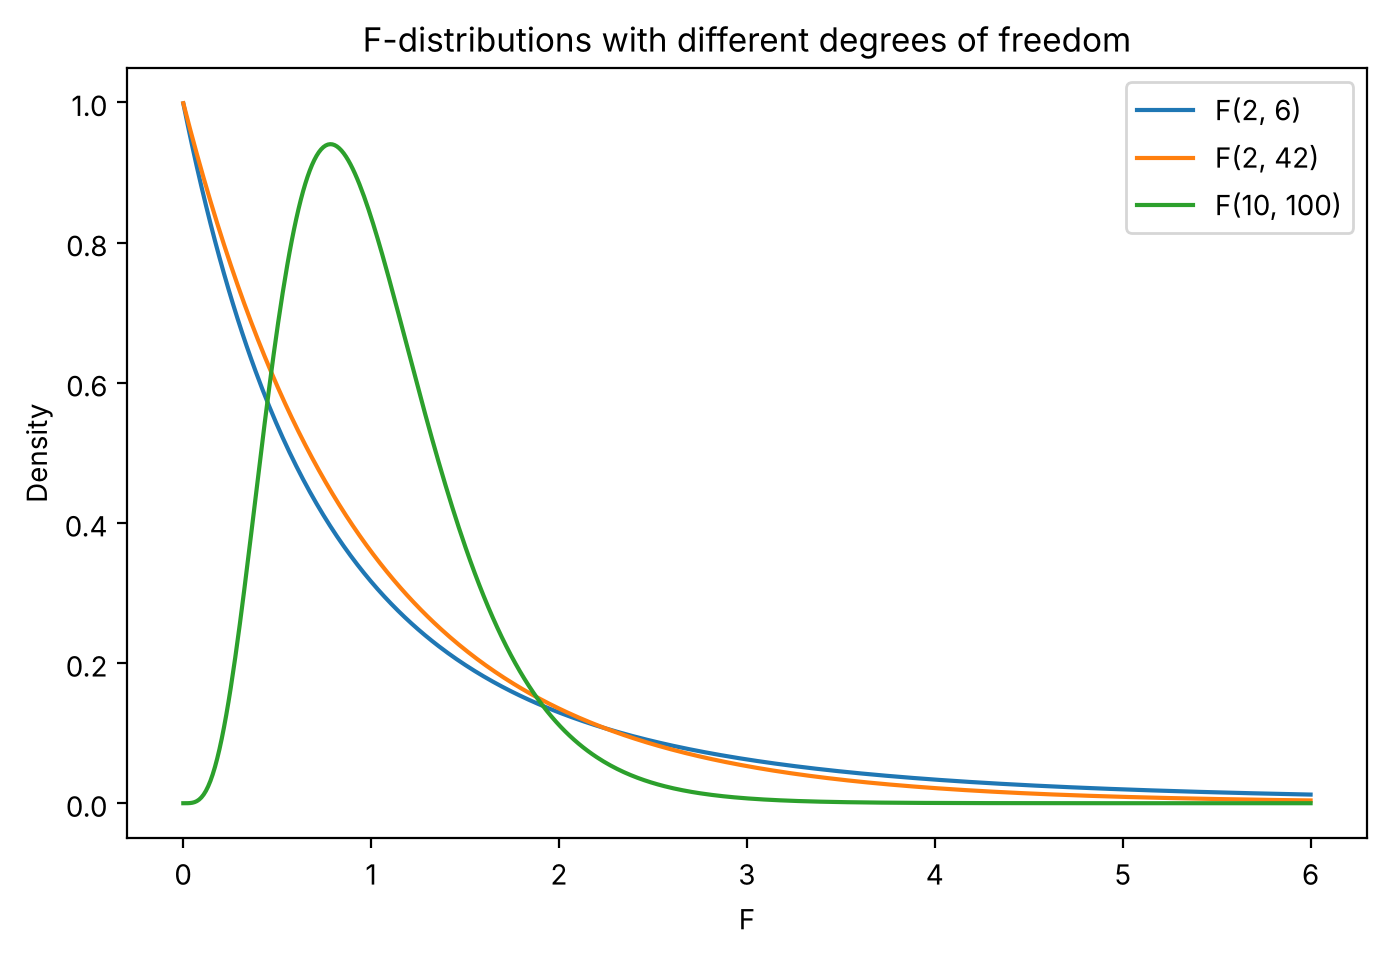

F_crit(2, 6) at alpha = .05: 5.14
F_crit(2, 9) at alpha = .05: 4.26
F_crit(3, 36) at alpha = .05: 2.87
F_crit(2, 42) at alpha = .05: 3.22

Colour constancy: p = 0.0053


In [7]:
import matplotlib.pyplot as plt

x = np.linspace(0.001, 6, 500)
plt.figure(figsize=(8, 5))
for df1, df2 in [(2, 6), (2, 42), (10, 100)]:
    plt.plot(x, stats.f.pdf(x, df1, df2), label=f"F({df1}, {df2})")
plt.xlabel("F")
plt.ylabel("Density")
plt.title("F-distributions with different degrees of freedom")
plt.legend()
plt.show()

for df1, df2 in [(2, 6), (2, 9), (3, 36), (2, 42)]:
    print(f"F_crit({df1}, {df2}) at alpha = .05: {stats.f.ppf(0.95, df1, df2):.2f}")

print(f"\nColour constancy: p = {stats.f.sf(5.00, 3, 36):.4f}")

**Answer**

- Critical values: $F_{crit}(2, 6) = 5.14$, $F_{crit}(2, 9) = 4.26$, $F_{crit}(3, 36) = 2.87$, $F_{crit}(2, 42) = 3.22$. They match the values used above and in the lecture.
- Colour-constancy study: $p = .005$.
- **Shape:** always positively (right-) skewed and $\geq 0$; with small df it is strongly skewed with a long right tail, and it becomes **more symmetric** (concentrated around 1) as the df increase. As a result, $F_{crit}$ shrinks as $df_W$ grows.
- **Right tail only:** F is a ratio of variances, so it cannot be negative. *Any* pattern of mean differences (in any direction) increases $MS_B$ and therefore increases F. Only large F values are evidence against $H_0$.
- **F-table:** numerator $df_1 = k - 1$ in the **columns**, denominator $df_2 = N - k$ in the **rows**.

### Part 7: Simulating the familywise error rate

Let's see the multiple-testing problem in action. We simulate many experiments in which **$H_0$ is true**: 5 groups with 15 participants each, all drawn from the same population (RT ~ Normal(500, 50)).

**Tasks**
1. Simulate 5,000 such experiments (`np.random.default_rng(2026)` for reproducibility).
2. For every experiment, run all 10 pairwise independent-samples t-tests (`stats.ttest_ind`) and record whether **at least one** p < .05.
3. Repeat step 2 with a Bonferroni-corrected threshold ($.05/10$).
4. For every experiment, run a one-way ANOVA (`stats.f_oneway`) and record whether p < .05.
5. Report the proportion of experiments with at least one false positive for each approach.

**Questions**
- Which approaches keep the familywise error rate near 5%?
- The formula $1 - 0.95^{10}$ predicts ≈ 40%. Is your simulated rate for uncorrected t-tests higher or lower? Why?

*Hint:* `ttest_ind` and `f_oneway` accept an `axis` argument, so you can avoid a slow loop over experiments by storing the data in an array of shape `(n_sim, k, n)`.

In [ ]:
import itertools

rng = np.random.default_rng(2026)
n_sim, k, n = 5000, 5, 15

# TODO 1: simulate data with shape (n_sim, k, n)

# TODO 2: p-values of all pairwise t-tests -> any p < .05 per experiment?

# TODO 3: same with the Bonferroni threshold

# TODO 4: one-way ANOVA p-values -> p < .05 per experiment?

# TODO 5: print the three proportions

**Solution**

In [9]:
import itertools

rng = np.random.default_rng(2026)
n_sim, k, n = 5000, 5, 15

data = rng.normal(500, 50, size=(n_sim, k, n))
pairs = list(itertools.combinations(range(k), 2))           # 10 pairs

# p-values: one column per pair, one row per simulated experiment
p_pairs = np.column_stack([
    stats.ttest_ind(data[:, i, :], data[:, j, :], axis=1).pvalue for i, j in pairs
])

fwer_uncorrected = (p_pairs < .05).any(axis=1).mean()
fwer_bonferroni = (p_pairs < .05 / len(pairs)).any(axis=1).mean()

p_anova = stats.f_oneway(*[data[:, g, :] for g in range(k)], axis=1).pvalue
rate_anova = (p_anova < .05).mean()

print(f"Number of pairwise tests: {len(pairs)}")
print(f"Formula 1 - 0.95^10:               {1 - 0.95 ** len(pairs):.3f}")
print(f"Simulated FWER, uncorrected t-tests: {fwer_uncorrected:.3f}")
print(f"Simulated FWER, Bonferroni t-tests:  {fwer_bonferroni:.3f}")
print(f"Simulated Type I error, ANOVA:       {rate_anova:.3f}")

Number of pairwise tests: 10
Formula 1 - 0.95^10:               0.401
Simulated FWER, uncorrected t-tests: 0.283
Simulated FWER, Bonferroni t-tests:  0.040
Simulated Type I error, ANOVA:       0.048


**Answer**

- **Uncorrected t-tests:** about **28–29%** of null experiments produce at least one "significant" difference, far above 5%.
- **Bonferroni-corrected t-tests:** ≈ **4%**, at or slightly below 5% (Bonferroni is conservative).
- **One-way ANOVA:** ≈ **5%**, the omnibus test controls the error rate at $\alpha$.
- The simulated uncorrected rate is **lower than 40%** because the 10 tests are **not independent**: each group is used in 4 comparisons, so the tests share data and their errors are correlated. The formula $1 - (1-\alpha)^m$ assumes independent tests, so it is an upper-bound approximation. The core message still holds: the familywise error rate grows quickly with the number of tests.

### Optional Follow-Up Thought
In Part 4 you saw that F depends on the **ratio** of between- to within-group variability. Imagine the speech-in-noise study had been run **within-subjects** (every participant tested in all three noise conditions). Which part of $SS_W$ could then be removed from the error term, and what would that do to F?
We will return to this idea next week with **repeated-measures ANOVA**.